DEVICE=device(type='cuda') | RTv4-S-hgnet.pth: 169,278,400 bytes


bbox 추출: 100/1500


bbox 추출: 200/1500


bbox 추출: 300/1500


bbox 추출: 400/1500


bbox 추출: 500/1500


... (7 outputs left out)

bbox 추출: 1300/1500


bbox 추출: 1400/1500


bbox 추출: 1500/1500
저장: D:\BUTAMI\examples\retrain\face_glasses.json | images=1500 | faces=1530 | glasses=937
학습 대상: {'no_glasses': 496, 'regular_glasses': 490, 'smart_glasses': 498} 제외: {'multiple_faces': 16}


epoch=20/100 loss=0.8792
epoch=40/100 loss=0.5538
epoch=60/100 loss=0.3238
epoch=80/100 loss=0.2122
epoch=100/100 loss=0.1565
train/test: 1186 298 accuracy: 0.9530201342281879 confusion: [[96, 3, 1], [0, 96, 2], [0, 8, 92]]


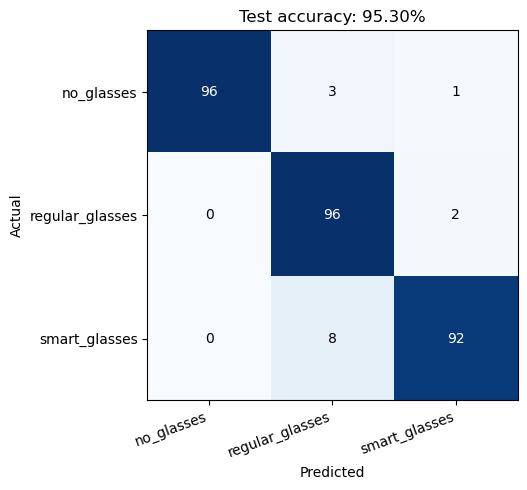

<All keys matched successfully>
MLP: clip_mlp_3class_2.pt | person/face/안경/분류 임계값: 0.5


200/3404 frames | 실제 영상 6.67초 | 처리 6.36초 | 4.65% 빠름


400/3404 frames | 실제 영상 13.35초 | 처리 13.65초 | 2.28% 느림


600/3404 frames | 실제 영상 20.02초 | 처리 19.57초 | 2.26% 빠름


800/3404 frames | 실제 영상 26.69초 | 처리 24.62초 | 7.78% 빠름


1000/3404 frames | 실제 영상 33.37초 | 처리 31.00초 | 7.09% 빠름


... (9 outputs left out)

3000/3404 frames | 실제 영상 100.10초 | 처리 97.73초 | 2.37% 빠름


3200/3404 frames | 실제 영상 106.77초 | 처리 100.34초 | 6.03% 빠름


3400/3404 frames | 실제 영상 113.45초 | 처리 103.36초 | 8.89% 빠름


3404/3404 frames 저장 완료: D:\BUTAMI\examples\retrain\temp_detr.mp4 | 실제 영상 113.58초 | 처리 103.48초 | 8.89% 빠름
산출물:
D:\BUTAMI\examples\retrain\clip_mlp_3class_2.pt
D:\BUTAMI\examples\retrain\face_glasses.json
D:\BUTAMI\examples\retrain\temp_detr.mp4


In [1]:
# 한 셀: data/images bbox 생성 → 고정 CLIP + MLP 재학습 → temp.mp4 추론
# bbox/학습은 기존 프로젝트 코드, 영상 처리는 examples/temp.ipynb를 기준으로 구성.
"""사람 이미지별 얼굴·안경 bbox를 원본 좌표의 COCO JSON으로 저장한다."""

import json
import math
import shutil
from pathlib import Path
from urllib.request import urlopen

import numpy as np
from PIL import Image, ImageOps

ROOT = Path('D:/BUTAMI')
OUT = ROOT / 'examples/retrain'
OUT.mkdir(exist_ok=True)
CLASSES = ("no_glasses", "regular_glasses", "smart_glasses")
BATCH_SIZE = 32
FACE_THRESHOLD = 0.5
GLASSES_THRESHOLD = 0.5
FACE_EXPAND = 1.8
FACE_MAX_SIZE = 640
MIN_FACE_AREA = 0.01
YUNET_URL = "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
CLASSIFIER_URL = "https://github.com/mantasu/glasses-detector/releases/download/v1.0.0/classification_anyglasses_shufflenet_v2_x1_0.pth"
GLASSES_URL = "https://github.com/mantasu/glasses-detector/releases/download/v1.0.0/segmentation_full_lraspp_mobilenet_v3_large.pth"


def ensure_weights(path, url):
    if path.is_file():
        with path.open("rb") as file:
            if path.stat().st_size > 100_000 and not file.read(128).startswith(b"version https://git-lfs"):
                return path
        raise ValueError(f"가중치 파일을 확인하세요: {path}")
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".part")
    try:
        with urlopen(url, timeout=60) as response, temporary.open("wb") as file:
            shutil.copyfileobj(response, file)
        with temporary.open("rb") as file:
            if temporary.stat().st_size <= 100_000 or file.read(128).startswith(b"version https://git-lfs"):
                raise ValueError(f"가중치 다운로드 결과를 확인하세요: {url}")
        temporary.replace(path)
    finally:
        temporary.unlink(missing_ok=True)
    return path


def clip_box(box, width, height):
    x, y, w, h = box
    if not all(math.isfinite(float(v)) for v in box) or w <= 0 or h <= 0:
        return None
    x0, y0 = max(0, min(width, math.floor(x))), max(0, min(height, math.floor(y)))
    x1, y1 = max(0, min(width, math.ceil(x + w))), max(0, min(height, math.ceil(y + h)))
    return [x0, y0, x1 - x0, y1 - y0] if x1 > x0 and y1 > y0 else None


def expand_box(box, width, height):
    x, y, w, h = box
    return clip_box([x - w * (FACE_EXPAND - 1) / 2, y - h * (FACE_EXPAND - 1) / 2, w * FACE_EXPAND, h * FACE_EXPAND], width, height)


def detect_faces(detector, image):
    import cv2

    width, height = image.size
    scale = min(1, FACE_MAX_SIZE / max(width, height))
    size = max(1, round(width * scale)), max(1, round(height * scale))
    bgr = np.asarray(image)[:, :, ::-1].copy()
    if size != image.size:
        bgr = cv2.resize(bgr, size)
    detector.setInputSize(size)
    _, faces = detector.detect(bgr)
    if faces is None:
        return []
    boxes = []
    for face in faces:
        score = float(face[-1])
        if not math.isfinite(score) or not FACE_THRESHOLD <= score <= 1:
            continue
        box = clip_box([face[0] * width / size[0], face[1] * height / size[1], face[2] * width / size[0], face[3] * height / size[1]], width, height)
        if box is not None:
            boxes.append((box, score))
    return boxes


def select_face(faces, width, height):
    """이미지 면적 1% 이상의 단일 얼굴을 자동 선택하고 나머지는 검수한다."""
    if not faces:
        return None, "no_face"
    candidates = [face for face in faces if face["score"] > FACE_THRESHOLD and face["area"] >= width * height * MIN_FACE_AREA]
    if not candidates:
        return None, "no_eligible_face"
    if len(candidates) > 1:
        return None, "multiple_faces"
    return candidates[0]["id"], "selected"


class GlassesExtractor:
    def __init__(self, root):
        import torch

        from torchvision.models import shufflenet_v2_x1_0
        from torchvision.models.segmentation import lraspp_mobilenet_v3_large

        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        weights = ensure_weights(root / "ckpt/pretrained/segmentation_full_lraspp_mobilenet_v3_large.pth", GLASSES_URL)
        self.model = lraspp_mobilenet_v3_large(weights=None, weights_backbone=None, num_classes=1)
        self.model.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
        self.model = self.model.to(self.device).eval()
        self.model.requires_grad_(False)
        weights = ensure_weights(root / "ckpt/pretrained/torch/checkpoints/classification_anyglasses_shufflenet_v2_x1_0.pth", CLASSIFIER_URL)
        self.classifier = shufflenet_v2_x1_0(weights=None)
        self.classifier.fc = torch.nn.Linear(1024, 1)
        self.classifier.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
        self.classifier = self.classifier.to(self.device).eval()
        self.classifier.requires_grad_(False)
        self.mean = torch.tensor([0.485, 0.456, 0.406], device=self.device).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225], device=self.device).view(1, 3, 1, 1)
        self.positions = torch.arange(256, device=self.device)

    def __call__(self, images):
        import torch

        pixels = np.stack([np.asarray(image.resize((256, 256))) for image in images]).transpose(0, 3, 1, 2).copy()
        with torch.inference_mode(), torch.autocast(device_type=self.device, dtype=torch.float16, enabled=self.device == "cuda"):
            pixels = torch.from_numpy(pixels).to(self.device, dtype=torch.float32).div_(255)
            pixels = (pixels - self.mean) / self.std
            probabilities = self.classifier(pixels).float().sigmoid().flatten()
            masks = self.model(pixels)["out"][:, 0] > 0
            rows, columns = masks.any(dim=2), masks.any(dim=1)
            # 마스크 대신 bbox 네 좌표와 착용 확률만 배치당 한 번 CPU로 전달한다.
            return torch.stack((
                torch.where(columns, self.positions, 256).amin(1),
                torch.where(rows, self.positions, 256).amin(1),
                torch.where(columns, self.positions + 1, 0).amax(1),
                torch.where(rows, self.positions + 1, 0).amax(1),
                probabilities,
            ), dim=1).cpu().tolist()


def project_box(bounds, crop):
    x0, y0, x1, y1 = bounds
    if x1 <= x0 or y1 <= y0:
        return None
    x, y, w, h = crop
    return clip_box([x + x0 * w / 256, y + y0 * h / 256, (x1 - x0) * w / 256, (y1 - y0) * h / 256], x + w, y + h)


def extract(root, detector, segmenter):
    data = {"images": [], "annotations": [], "categories": [{"id": 1, "name": "face"}, {"id": 2, "name": "glasses"}]}
    paths = [path for label in CLASSES for path in sorted((root / "data/images" / label).glob("*.jpg"))]
    if not paths:
        raise ValueError(f"입력 이미지를 확인하세요: {root / 'data/images'}")
    pending = []

    def annotate(image_id, category, box, score, face_id=None):
        annotation = {"id": len(data["annotations"]) + 1, "image_id": image_id, "category_id": category,
                      "bbox": box, "area": box[2] * box[3], "iscrowd": 0, "score": score}
        if face_id is not None:
            annotation["face_id"] = face_id
        data["annotations"].append(annotation)
        return annotation

    def flush():
        bounds = segmenter([item[3] for item in pending])
        if len(bounds) != len(pending):
            raise ValueError("안경 추출 결과와 입력 이미지 수가 다릅니다.")
        for (image_id, face, crop, _), result in zip(pending, bounds):
            probability = float(result[4])
            if not math.isfinite(probability) or not 0 <= probability <= 1:
                raise ValueError("안경 착용 확률을 확인하세요.")
            face["glasses_probability"] = probability
            if probability < GLASSES_THRESHOLD:
                face["glasses_status"] = "below_threshold"
                continue
            box = project_box(result[:4], crop)
            face["glasses_status"] = "detected" if box is not None else "empty_mask"
            if box is not None:
                annotate(image_id, 2, box, probability, face["id"])
        pending.clear()

    for image_id, path in enumerate(paths, 1):
        with Image.open(path) as original:
            image = ImageOps.exif_transpose(original).convert("RGB")
        width, height = image.size
        record = {"id": image_id, "file_name": path.relative_to(root / "data/images").as_posix(), "width": width, "height": height}
        data["images"].append(record)
        faces = []
        for box, score in detect_faces(detector, image):
            face = annotate(image_id, 1, box, score)
            faces.append(face)
            crop = expand_box(box, width, height)
            x, y, w, h = crop
            pending.append((image_id, face, crop, image.crop((x, y, x + w, y + h))))
            if len(pending) == BATCH_SIZE:
                flush()
        record["selected_face_id"], record["selection_status"] = select_face(faces, width, height)
        if image_id % 100 == 0:
            print(f"bbox 추출: {image_id}/{len(paths)}")
    if pending:
        flush()
    output = OUT / "face_glasses.json"
    output.parent.mkdir(parents=True, exist_ok=True)
    temporary = output.with_suffix(".json.tmp")
    try:
        temporary.write_text(json.dumps(data, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
        temporary.replace(output)
    finally:
        temporary.unlink(missing_ok=True)
    print(f"저장: {output} | images={len(paths)} | faces={sum(a['category_id'] == 1 for a in data['annotations'])} | glasses={sum(a['category_id'] == 2 for a in data['annotations'])}")
    return data


from pathlib import Path
from time import perf_counter
import sys
import cv2
import numpy as np
import torch
import torchvision.transforms as T
from PIL import Image
from IPython.display import Video, display

ROOT = Path('D:/BUTAMI')
SOURCE = ROOT / 'data/videos/temp.mp4'
WEIGHTS = ROOT / 'ckpt/pretrained/RTv4-S-hgnet.pth'
OUTPUT = OUT / 'temp_detr.mp4'
FACE_WEIGHTS = ROOT / 'ckpt/pretrained/face_detection_yunet_2023mar.onnx'
THRESHOLD = 0.5
FACE_THRESHOLD = 0.5
BATCH_SIZE = 8
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert SOURCE.is_file(), SOURCE
assert WEIGHTS.is_file(), WEIGHTS
assert FACE_WEIGHTS.is_file(), FACE_WEIGHTS
sys.path.insert(0, str(ROOT / 'third_party/RT-DETRv4'))
from engine.core import YAMLConfig
from engine.data.dataset.coco_dataset import mscoco_category2name

print(f'{DEVICE=} | {WEIGHTS.name}: {WEIGHTS.stat().st_size:,} bytes')

from transformers import CLIPModel, CLIPProcessor
import math

def build_samples(data):
    annotations = {ann["id"]: ann for ann in data["annotations"]}
    glasses_faces = {ann["face_id"] for ann in data["annotations"] if ann["category_id"] == 2}
    samples, excluded = [], []
    for image in data["images"]:
        if "selected_face_id" not in image:
            raise ValueError("갱신한 phase2a_extract/bbox/extract_bbox.py로 JSON을 다시 생성하세요.")
        face_id = image["selected_face_id"]
        if face_id is None:
            excluded.append({"image_id": image["id"], "file_name": image["file_name"],
                             "reason": image.get("selection_status", "face_review")})
            continue
        face = annotations.get(face_id)
        if face is None or face["category_id"] != 1 or face["image_id"] != image["id"]:
            raise ValueError(f"선택한 얼굴 주석을 확인하세요: {image['file_name']}")
        if face.get("score", 0) <= FACE_THRESHOLD:
            excluded.append({"image_id": image["id"], "file_name": image["file_name"], "reason": "face_score"})
            continue
        if "glasses_probability" not in face or "glasses_status" not in face:
            raise ValueError("2a를 다시 실행해 얼굴별 안경 확률·상태를 저장하세요.")
        label = CLASSES.index(image["file_name"].split("/")[0])
        samples.append({"image_id": image["id"], "file_name": image["file_name"], "face_id": face_id,
                        "bbox": face["bbox"], "label": label, "face_score": face["score"],
                        "glasses_probability": face["glasses_probability"], "glasses_status": face["glasses_status"],
                        "glasses_bbox_present": face_id in glasses_faces})
    return samples, excluded

def stratified_split(samples):
    generator = random.Random(SEED)
    train, test = [], []
    for label in range(len(CLASSES)):
        ids = [i for i, sample in enumerate(samples) if sample["label"] == label]
        if len(ids) < 2:
            raise ValueError(f"{CLASSES[label]}: 선택된 얼굴 이미지가 최소 2장 필요합니다.")
        generator.shuffle(ids)
        split = max(1, min(len(ids) - 1, int(len(ids) * (1 - TEST_RATIO))))
        train.extend(ids[:split])
        test.extend(ids[split:])
    return train, test

def crop_face(image, box):
    x, y, w, h = box
    margin = (FACE_EXPAND - 1) / 2
    return image.crop((max(0, math.floor(x - w * margin)), max(0, math.floor(y - h * margin)),
                       min(image.width, math.ceil(x + w * (1 + margin))), min(image.height, math.ceil(y + h * (1 + margin)))))

import random
from collections import Counter
from transformers import CLIPModel, CLIPProcessor
from torch.utils.data import Dataset, DataLoader

SEED, TEST_RATIO, HIDDEN_DIM, EPOCHS, LEARNING_RATE = 42, 0.2, 128, 100, 1e-3
BACKBONE = 'openai/clip-vit-base-patch32'
MLP_WEIGHTS = OUT / 'clip_mlp_3class_2.pt'
torch.manual_seed(SEED)
cv2.setNumThreads(1)
BATCH_SIZE = 32
face_detector = cv2.FaceDetectorYN.create(str(FACE_WEIGHTS), '', (640, 640), FACE_THRESHOLD, 0.3, 5000)
glasses = GlassesExtractor(ROOT)
data = extract(ROOT, face_detector, glasses)
samples, excluded = build_samples(data)
train_ids, test_ids = stratified_split(samples)
print('학습 대상:', dict(Counter(CLASSES[s['label']] for s in samples)), '제외:', dict(Counter(s['reason'] for s in excluded)))
processor = CLIPProcessor.from_pretrained(BACKBONE, cache_dir=str(ROOT / 'ckpt/pretrained/clip'), local_files_only=True)
clip = CLIPModel.from_pretrained(BACKBONE, cache_dir=str(ROOT / 'ckpt/pretrained/clip'), local_files_only=True).to(DEVICE).eval()
clip.requires_grad_(False)
class Faces(Dataset):
    def __len__(self): return len(samples)
    def __getitem__(self, i):
        with Image.open(ROOT / 'data/images' / samples[i]['file_name']) as image:
            return processor(images=crop_face(ImageOps.exif_transpose(image).convert('RGB'), samples[i]['bbox']), return_tensors='pt')['pixel_values'][0]
features = []
with torch.inference_mode():
    for pixels in DataLoader(Faces(), batch_size=64, num_workers=0, pin_memory=DEVICE.type == 'cuda'):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == 'cuda'):
            feature = clip.visual_projection(clip.vision_model(pixel_values=pixels.to(DEVICE, non_blocking=True)).pooler_output)
        features.append(torch.nn.functional.normalize(feature.float(), dim=-1))
features = torch.cat(features)
labels = torch.tensor([s['label'] for s in samples], device=DEVICE)
x_train, y_train = features[train_ids].clone(), labels[train_ids]
mlp = torch.nn.Sequential(torch.nn.Linear(features.shape[1], HIDDEN_DIM), torch.nn.ReLU(), torch.nn.Linear(HIDDEN_DIM, 3)).to(DEVICE)
optimizer = torch.optim.AdamW(mlp.parameters(), lr=LEARNING_RATE)
mlp.train()
for epoch in range(EPOCHS):
    optimizer.zero_grad(set_to_none=True)
    loss = torch.nn.functional.cross_entropy(mlp(x_train), y_train)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 20 == 0: print(f'epoch={epoch+1}/{EPOCHS} loss={loss.item():.4f}')
mlp.eval()
with torch.inference_mode():
    pred = mlp(features[test_ids]).argmax(1)
    cm = torch.bincount(labels[test_ids] * 3 + pred, minlength=9).reshape(3, 3).cpu()
print('train/test:', len(train_ids), len(test_ids), 'accuracy:', cm.diag().sum().item()/len(test_ids), 'confusion:', cm.tolist())
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm.numpy(), cmap='Blues')
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(cm[i, j].item()), ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES, xlabel='Predicted', ylabel='Actual', title=f'Test accuracy: {cm.diag().sum().item()/len(test_ids):.2%}')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
fig.tight_layout()
plt.show()

torch.save({'state_dict': {k:v.detach().cpu() for k,v in mlp.state_dict().items()}, 'classes': list(CLASSES),
            'backbone': BACKBONE, 'feature_dim': features.shape[1], 'hidden_dim': HIDDEN_DIM, 'normalize_features': True,
            'face_expand': FACE_EXPAND, 'face_threshold': FACE_THRESHOLD, 'seed': SEED,
            'epochs': EPOCHS, 'learning_rate': LEARNING_RATE, 'train_files': [samples[i]['file_name'] for i in train_ids],
            'test_files': [samples[i]['file_name'] for i in test_ids], 'confusion_matrix': cm.tolist()}, MLP_WEIGHTS)
del features, x_train, y_train, optimizer
NORMALIZE = True
BATCH_SIZE = 8

cfg = YAMLConfig(str(ROOT / 'third_party/RT-DETRv4/configs/rtv4/rtv4_hgnetv2_s_coco.yml'))
cfg.yaml_cfg['HGNetv2']['pretrained'] = False
checkpoint = torch.load(WEIGHTS, map_location='cpu', weights_only=False)
model = cfg.model
print(model.load_state_dict(checkpoint['ema']['module'] if 'ema' in checkpoint else checkpoint['model']))
# 고정 위치 임베딩도 모델과 함께 장치로 이동하도록 등록합니다.
for idx in model.encoder.use_encoder_idx:
    name = f'pos_embed{idx}'
    if hasattr(model.encoder, name) and name not in model.encoder._buffers:
        embedding = getattr(model.encoder, name)
        delattr(model.encoder, name)
        model.encoder.register_buffer(name, embedding, persistent=False)
model = model.deploy().to(DEVICE).eval()
postprocessor = cfg.postprocessor.deploy().to(DEVICE).eval()
transform = T.Compose([T.Resize((640, 640)), T.ToTensor()])
classes = list(mscoco_category2name.values())
del checkpoint

PERSON = classes.index('person')
face_detector = cv2.FaceDetectorYN.create(str(FACE_WEIGHTS), '', (320, 320), FACE_THRESHOLD, 0.3, 5000)

CLASS_NAMES = ('normal', 'glass', 'smart')
CLASS_COLORS = ((0, 0, 255), (0, 255, 255), (255, 0, 0))  # OpenCV BGR
print(f'MLP: {MLP_WEIGHTS.name} | person/face/안경/분류 임계값: {THRESHOLD}')

def draw_box(frame, box, caption, color):
    x1, y1, x2, y2 = box
    cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
    cv2.putText(frame, caption, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)

cap = cv2.VideoCapture(str(SOURCE))
assert cap.isOpened(), f'영상 열기 실패: {SOURCE}'
fps = cap.get(cv2.CAP_PROP_FPS)
width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
assert fps > 0 and width > 0 and height > 0, '영상 메타데이터 확인 필요'
writer = cv2.VideoWriter(str(OUTPUT), cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))
assert writer.isOpened(), f'영상 저장기 열기 실패: {OUTPUT}'
sizes = torch.tensor([[width, height]], device=DEVICE).expand(BATCH_SIZE, -1)
processed = 0
started = perf_counter()
try:
    with torch.inference_mode():
        while True:
            frames = []
            for _ in range(BATCH_SIZE):
                ok, frame = cap.read()
                if not ok:
                    break
                frames.append(frame)
            if not frames:
                break
            images = torch.stack([transform(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))) for frame in frames]).to(DEVICE)
            labels, boxes, scores = postprocessor(model(images), sizes[:len(frames)])
            detections = torch.cat((boxes, labels.unsqueeze(-1), scores.unsqueeze(-1)), -1).cpu().numpy()
            people = [rows[(rows[:, 4] == PERSON) & (rows[:, 5] >= THRESHOLD)] for rows in detections]
            faces, crops = [], []
            # 원본에서 얼굴과 1.8배 crop을 수집한 뒤 배치 추론합니다.
            for i, (frame, rows) in enumerate(zip(frames, people)):
                for x1, y1, x2, y2, _, score in rows:
                    x1, x2 = np.clip([np.floor(x1), np.ceil(x2)], 0, width).astype(int)
                    y1, y2 = np.clip([np.floor(y1), np.ceil(y2)], 0, height).astype(int)
                    if x2 - x1 < 16 or y2 - y1 < 16:
                        continue
                    face_detector.setInputSize((x2 - x1, y2 - y1))
                    _, found = face_detector.detect(np.ascontiguousarray(frame[y1:y2, x1:x2]))
                    if found is None:
                        continue
                    for face in found:
                        if face[-1] < FACE_THRESHOLD:
                            continue
                        fx, fy, fw, fh = face[:4]
                        fx1, fy1 = max(x1, math.floor(x1 + fx)), max(y1, math.floor(y1 + fy))
                        fx2, fy2 = min(x2, math.ceil(x1 + fx + fw)), min(y2, math.ceil(y1 + fy + fh))
                        if fx2 <= fx1 or fy2 <= fy1:
                            continue
                        margin = (FACE_EXPAND - 1) / 2
                        cx1, cy1 = max(0, math.floor(fx1 - (fx2 - fx1) * margin)), max(0, math.floor(fy1 - (fy2 - fy1) * margin))
                        cx2, cy2 = min(width, math.ceil(fx2 + (fx2 - fx1) * margin)), min(height, math.ceil(fy2 + (fy2 - fy1) * margin))
                        faces.append((i, (fx1, fy1, fx2, fy2), float(face[-1]), (cx1, cy1, cx2 - cx1, cy2 - cy1)))
                        crops.append(Image.fromarray(cv2.cvtColor(frame[cy1:cy2, cx1:cx2], cv2.COLOR_BGR2RGB)))
            predictions, bounds = [], []
            for offset in range(0, len(crops), 32):
                batch = crops[offset:offset + 32]
                pixels = processor(images=batch, return_tensors='pt')['pixel_values'].to(DEVICE)
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == 'cuda'):
                    features = clip.visual_projection(clip.vision_model(pixel_values=pixels).pooler_output)
                features = features.float()
                if NORMALIZE:
                    features = torch.nn.functional.normalize(features, dim=-1)
                predictions.extend(mlp(features).softmax(1).cpu().tolist())
                bounds.extend(glasses(batch))
            for frame, rows in zip(frames, people):
                for x1, y1, x2, y2, _, score in rows:
                    x1, x2 = np.clip([x1, x2], 0, width - 1).astype(int)
                    y1, y2 = np.clip([y1, y2], 0, height - 1).astype(int)
                    draw_box(frame, (x1, y1, x2, y2), f'person {score:.2f}', (0, 255, 0))
            for (i, (x1, y1, x2, y2), face_score, crop), probability, bound in zip(faces, predictions, bounds):
                frame = frames[i]
                face_box = (x1, y1, min(width - 1, x2), min(height - 1, y2))
                label = int(np.argmax(probability))
                confidence = probability[label]
                if confidence < THRESHOLD:
                    draw_box(frame, face_box, f'face {face_score:.2f}', (0, 0, 255))
                    continue
                color = CLASS_COLORS[label]
                caption = f'{CLASS_NAMES[label]} {confidence:.2f}'
                box = project_box(bound[:4], crop) if label > 0 and bound[4] >= THRESHOLD else None
                if box is not None:
                    draw_box(frame, face_box, f'face {face_score:.2f}', (0, 0, 255))
                    gx, gy, gw, gh = box
                    draw_box(frame, (gx, gy, min(width - 1, gx + gw), min(height - 1, gy + gh)), caption, color)
                else:
                    draw_box(frame, face_box, f'face {face_score:.2f}', (0, 0, 255))
                    if label == 0:
                        cv2.putText(frame, caption, (x1, min(height - 5, y1 + 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1, cv2.LINE_AA)
            for frame in frames:
                writer.write(frame)
            processed += len(frames)
            if processed % (BATCH_SIZE * 25) == 0:
                elapsed = perf_counter() - started
                print(f'{processed}/{total} frames | 실제 영상 {processed / fps:.2f}초 | 처리 {elapsed:.2f}초 | {abs(1 - elapsed / (processed / fps)) * 100:.2f}% {"빠름" if elapsed <= processed / fps else "느림"}', flush=True)
finally:
    cap.release()
    writer.release()
elapsed = perf_counter() - started
print(f'{processed}/{total} frames 저장 완료: {OUTPUT} | 실제 영상 {processed / fps:.2f}초 | 처리 {elapsed:.2f}초 | {abs(1 - elapsed / (processed / fps)) * 100:.2f}% {"빠름" if elapsed <= processed / fps else "느림"}')

print('산출물:', MLP_WEIGHTS, OUT / 'face_glasses.json', OUTPUT, sep='\n')
